# Homework 7: Optimization and Fourier analysis

**Course title:** Computer Simulation Methods in Physics (Phys 4071/5071; Fall 2025)  
**This homework assignment is due October 29, 2025, at 8 am.**   
(Submission via the shared `GitHub` repository.)

**Before you submit your homework, make sure that you click `Kernel > Restart & Run All`**.

## Lagrange multipliers

Sometimes one has to find the extrema of a function $f(x_1,x_2,\ldots, x_n)$ subject to the constraint that $g(x_1,x_2,\ldots,x_n) \overset{!}{=} 0$, with a given function $g$.

For example, consider a Gaussian on the two-dimensional $x-y$ plane, i.e., $f(x,y) = \exp(-(x^2 + y^2))$. 
This function has one maximum at $x_m = y_m = 0$ at which the gradient vanishes. 

Now suppose we constrain the search for a maximum to, e.g., a one-dimensional subspace, which does not go through the origin. Let's say $g(x,y) = y - (x-1)^2 - 2 \overset{!}{=} 0$.

In that case, the maximum of $f(x,y)$ is not at the origin anymore but at a location along the parabola. The **method of Lagrange multipliers** is a commen strategy to deal with such constrained optimization problem.

This method introduces the Lagrange function 

$$
F(x_1,x_2,\ldots,x_n,\lambda) \equiv f(x_1,x_2,\ldots,x_n) + \lambda g(x_1,x_2,\ldots,x_n)
$$

with the Lagrange multiplier $\lambda$ and the equation constraint

$$ 
g(x_1,x_2,\ldots,x_n) = 0 \,.
$$

The extrema subject to this equation constraint are now obtained by solving 

\begin{equation}
{\partial F \over \partial x_i} = 0  \quad \mathrm{and} \quad
{\partial F \over \partial \lambda} = 0 \,,
\end{equation}

with $i=1,2,\ldots,n$. Note that the derivative with respect to $\lambda$ returns the original equation constraint. 
This is a root-finding problem for the extended set of variables $x_1,x_2,\ldots,x_n,\lambda$, where the Lagrange multiplier is just another variable. 

1. Plot contour lines of $f(x,y)$ and the constraint in one graph and estimate the location of the constrained maximum. 
2. Write a `python` program to find the maximum of $f(x,y) = \exp(-(x^2 + y^2))$ subject to the constraint $y(x) = (x-1)^2+2$. 
3. Check numerically that the result obtained in 2.) is indeed a local maximum.

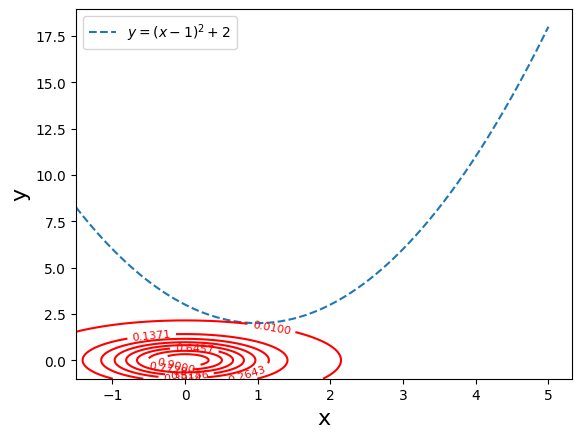

By visual inspection and kowing maximum ordered pair comes from constraint being tangent to closest contour line then (x = 0.8, y = 2.1).


In [1]:
#Q1 Part 1.) Lagrange Multipliers 

import math
import numpy as np 
import matplotlib.pyplot as plt 

# defining contour function 
def f(x,y): 
    '''
    This function essentially defines the Gaussian for contour plotting. 
    
    Parameters
    ----------
    x: numpy array 
    x-grid points 

    y: numpy array 
    y-gridpoints 

    Return
    ------
    float or numpy array 
    Essentially, values for every (x, y) pair for contour plotting and heatmap values. 

    '''
    return (np.exp(-x**2 -y**2))

# defining constraint 
cont = lambda x: ((x-1.0)**2 + 2.0)

# defining gridpoints for constraint and contour
x = np.linspace(-1.5, 3.0, 200) 
y = np.linspace(-1.0, 6.0, 200) 
x_line = np.linspace(-1.5, 5.0, 400)  
y_line = cont(x_line)   

# initializing contour values and grid
u,v = np.meshgrid(x, y)
H = f(u, v)

# necessary plotting
contour_levels = np.linspace(0.01,0.9,8)
plt.plot(x_line, y_line, "--", label = rf"$y = (x-1)^2 + 2$")
cs = plt.contour(u, v, H, levels = contour_levels,  colors="red")
plt.clabel(cs, inline=True, fontsize = 8)
plt.xlabel("x", fontsize = 16)
plt.ylabel("y", fontsize = 16)
plt.legend(loc='best')
plt.show()


print("By visual inspection and kowing maximum ordered pair comes from constraint being tangent to closest contour line then (x = 0.8, y = 2.1).")


In [2]:
#Q1 Part 2.) Gauss-Newton 

import numpy as np
import numpy.linalg as linalg

def F(x):
    '''
    Lagrange function with Gaussian term (x,y) and lambda in Lagrange multiplier based on the constraint of g(x,y). 

    Parameters
    ----------
    x: numpy array 
    each array indexing corresponds to (x,y, lambda) 

    Return 
    ------
    numpy array 
    value of the Lagrange function. 
    '''
    return (np.exp(-(x[0]**2 + x[1]**2)) + x[2]*(x[1] - (x[0] - 1.0)**2 - 2.0))
    
def gradf(x):
    ''' Gradient vector with elements of first partials. Vital to later Gauss-Newton

    Parameters
    ----------
    x: numpy array 
    each array indexing corresponds to (x,y, lambda) 

    Return
    ------
    numpy array 
    value and each element of the gradient vector

    '''
    J = np.empty(3)
    J[0] = -2.0*x[0]*np.exp(-(x[0]**2 + x[1]**2))- 2.0*x[2]*(x[0] - 1.0)
    J[1] = -2.0*x[1]*np.exp(-(x[0]**2 + x[1]**2)) + x[2] 
    J[2] = x[1] - (x[0] - 1.0)**2 - 2.0 
    return J

def Hessian(x):
    ''' Hessian matrix that has elements that contain all terms of 2nd partials, this is also needed for the Gauss-Newton method. 

    Parameters
    ----------
    x: numpy array 
    each array indexing corresponds to (x,y, lambda) 

    Return
    ------
    numpy array 
    value and each element of the Hessian Matrix.

    '''
    H = np.empty((3,3))
    H[0,0] = np.exp(-(x[0]**2 + x[1]**2))*(4.0*x[0]**2 - 2.0) - 2.0*x[2]
    H[0,1] = 4.0*x[0]*x[1]*np.exp(-(x[0]**2 + x[1]**2)) 
    H[0,2] = -2.0*(x[0] - 1.0) 
    H[1,0] = 4.0*x[0]*x[1]*np.exp(-(x[0]**2 + x[1]**2))
    H[1,1] = -2.0*np.exp(-(x[0] + x[1]))
    H[1,2] = 1.0 
    H[2,0] = -2.0*(x[0] - 1.0)
    H[2,1] = 1.0 
    H[2,2] = 0.0 
    return H

# start point
x1 = np.array([1.0, 1.5, 4.0])

# Gauss Newton algorithm
for i in range(1, 100, 1):
    x2 = x1 + np.linalg.solve(Hessian(x1), -gradf(x1))
    error = linalg.norm(x2-x1)
    if i < 5 or i % 5 == 0:
        print(f"iter #: {i}\tx: [{x2[0]:.6f}, {x2[1]:.6f}, {x2[2]:.6f}]\terror: {error:e}")
    if error < 1e-12:
        break
    else:
        x1 = x2   

iter #: 1	x: [1.004894, 2.000000, 0.197269]	error: 3.835464e+00
iter #: 2	x: [0.968911, 1.999672, 0.028586]	error: 1.724783e-01
iter #: 3	x: [0.736982, 2.015387, 0.043193]	error: 2.329193e-01
iter #: 4	x: [0.809710, 2.030921, 0.037977]	error: 7.455051e-02
iter #: 5	x: [0.809013, 2.036476, 0.034781]	error: 6.445951e-03
iter #: 10	x: [0.803070, 2.038781, 0.033509]	error: 3.818989e-05
iter #: 15	x: [0.803056, 2.038787, 0.033505]	error: 9.193493e-08
iter #: 20	x: [0.803056, 2.038787, 0.033505]	error: 2.210331e-10
iter #: 25	x: [0.803056, 2.038787, 0.033505]	error: 5.313760e-13


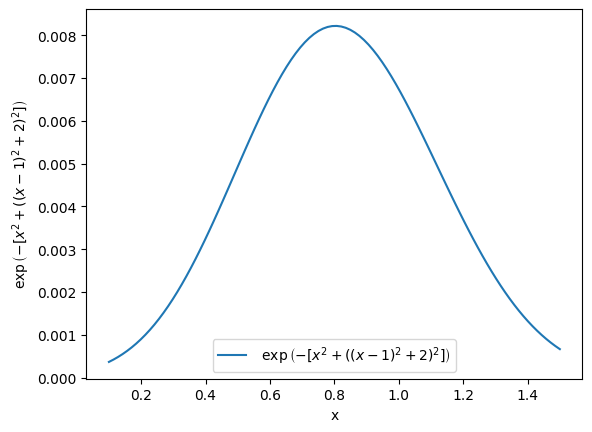

Plot clearly shows that 1-D projection with gaussian y-arg as constraint that maximum is around x = 0.8 so an assumption is safe to say y = 2.0 approximately.

 This itself shows Gauss-Newton Results of Part 2 are valid.


In [3]:
#Q1 Part 2.) Maxima Proof 

import numpy as np
import numpy.linalg as linalg
import matplotlib.pyplot as plt 

# Defining arguments for plotting 
x = np.linspace(0.1, 1.5, 100) # gridspace for x 
Func = f(x, cont(x)) # Gaussian with constraint arguement 


# plotting Gaussian with constraint applied
plt.plot(x, Func, label = rf" $\exp\left(-\left[x^2 + \left((x - 1)^2 + 2\right)^2\right]\right)$")
plt.xlabel("x") 
plt.ylabel(r"$\exp\left(-\left[x^2 + \left((x - 1)^2 + 2\right)^2\right]\right)$")
plt.legend(loc='best')
plt.show()


print("Plot clearly shows that 1-D projection with gaussian y-arg as constraint that maximum is around x = 0.8 so an assumption is safe to say y = 2.0 approximately.")
print("\n This itself shows Gauss-Newton Results of Part 2 are valid.")



## Discrete Fourier Transform vs. Discrete Cosine Transformation 

Discrete Fourier Transformation requires that the last data point be the same as the first data point, i.e., that the data can be considered periodic with the period of the sampling time. If the last data point is different from the first one, this can lead to artifacts of the Fourier coefficients. 

a) Write a `Python` program similar to the one we worked with in class, in which you read in the data in the file `dow2.txt` and plot them. Next, smooth the data by calculating its Fourier transform, setting all but the first 2% of the coefficients to zero, and inverting the transform again, plotting the result on the same graph as the original data. 

You should see that the data are smoothed, but with an additional artifact. At the beginning and end of the plot, you should see large deviations away from the true smoothed function. These occur because the function is required to be periodic, i.e., its last value must be the same as its first, so it needs to deviate substantially from the correct value to make the two ends of the function meet. 

In some situations (including this one), this behavior is unsatisfactory. If we want to use the Fourier transform for smoothing, we prefer that it does not introduce artifacts of this kind.

b) Perform a Discrete Cosine Transform on the data in `dow2.txt` and, again, discard all but the first 2% of the coefficients, invert the transform, and plot the result. You should see a significant improvement, with less distortion of the function at the ends of the interval. This occurs because the cosine transform does not force the value of the function to be the same at both ends.

Because of the artifacts introduced by the strict periodicity of the DFT, the DCT is favored for many applications, such as audio compression. The artifacts can degrade the
sound quality of compressed audio and the cosine transforms generally give better results. 

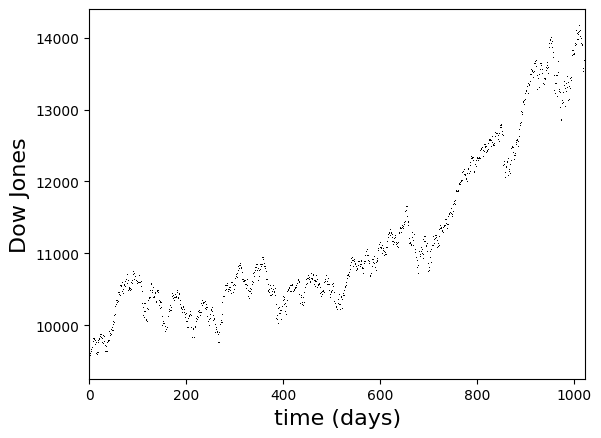

number of coefficients = 20 (compression rate: 96.1%)


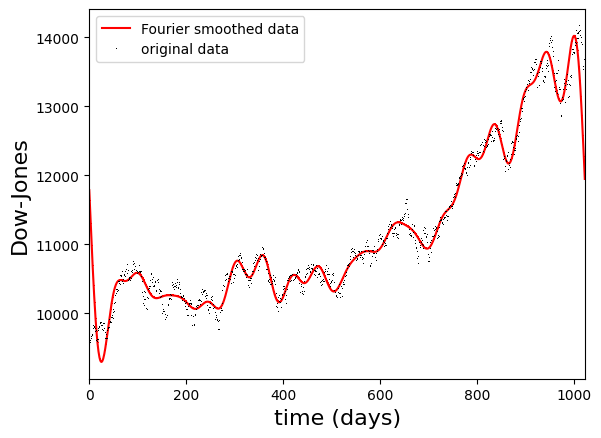

In [4]:
# Fourier Transforms Part A.)
import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import rfft, irfft


# Dow Jones Data
y = np.loadtxt("dow2.txt",float)

# Original Plot 
plt.plot(y, linestyle='', marker=',', color='black')
plt.xlim(0, len(y))
plt.xlabel("time (days)", fontsize=16)
plt.ylabel("Dow Jones", fontsize=16)
plt.show()


# FFT:
c = rfft(y)
# duration of time series in days
T_s = len(y)
# filtering coefficients
fc = 2e-2  #2-percent cutoff
nc = int(fc*T_s)
print("number of coefficients =", nc, f"(compression rate: {(1.-nc/len(c))*100:.1f}%)")
assert nc < len(c), "filter too high"
c[nc:len(c)]=0


#inverse FFT 
y_filtered = irfft(c)


#Final plotting
plt.plot(y_filtered, linestyle='-', marker=',', color='red', label="Fourier smoothed data")
plt.plot(y,linestyle='', marker=',', color='black', label="original data")
plt.xlabel("time (days)", fontsize=16)
plt.ylabel("Dow-Jones", fontsize=16)
plt.xlim(0, len(y))
plt.legend()
plt.show()


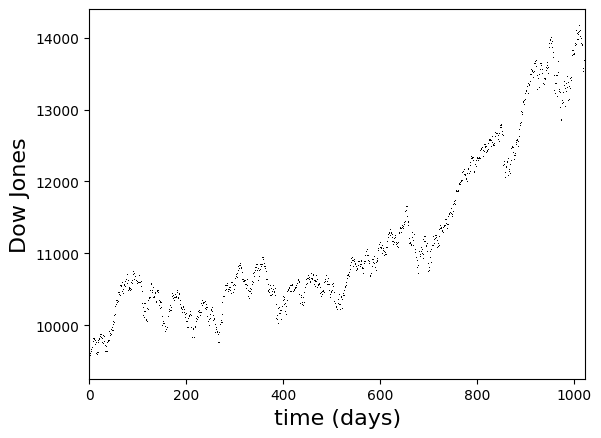

number of coefficients = 20 (compression rate: 98.0%)


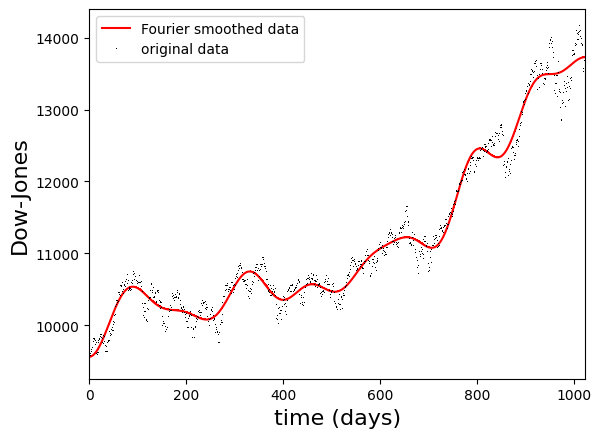

In [5]:
# Fourier Transforms Part B.)
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import dct, idct


# Dow Jones Data
y = np.loadtxt("dow2.txt",float)

# Original Plot 
plt.plot(y, linestyle='', marker=',', color='black')
plt.xlim(0, len(y))
plt.xlabel("time (days)", fontsize=16)
plt.ylabel("Dow Jones", fontsize=16)
plt.show()


# DCT:
c = dct(y)
# duration of time series in days
T_s = len(y)
# filtering coefficients
fc = 2e-2  #2-percent cutoff
nc = int(fc*T_s) #putting it in int form
print("number of coefficients =", nc, f"(compression rate: {(1.-nc/len(c))*100:.1f}%)")
assert nc < len(c), "filter too high"
c[nc:len(c)]=0


#inverse DCT 
y_filtered = idct(c)


#Final plotting
plt.plot(y_filtered, linestyle='-', marker=',', color='red', label="Fourier smoothed data")
plt.plot(y,linestyle='', marker=',', color='black', label="original data")
plt.xlabel("time (days)", fontsize=16)
plt.ylabel("Dow-Jones", fontsize=16)
plt.xlim(0, len(y))
plt.legend()
plt.show()